# Nguyễn Thành Trí - MSSV: 6451071079
# BÁO CÁO BÀI TẬP PHẦN 1 - TRANG 28-29 (BÀI 2)
## TIỀN XỬ LÝ DỮ LIỆU BANK MARKETING (`bank.csv`)

---

### MỤC LỤC NỘI DUNG:
1. **Câu 1**: Nhập dữ liệu và thống kê các thông tin cơ bản.
2. **Câu 2**: Thống kê danh sách các thuộc tính thiếu / 'unknown' nhiều nhất.
3. **Câu 3**: Khảo sát sự liên quan giữa thuộc tính Nhân khẩu học và Quyết định đăng ký (`y`).
4. **Câu 4**: Khảo sát sự liên quan giữa thuộc tính Chiến dịch liên lạc và Quyết định `y`.
5. **Câu 5**: Tiền xử lý dữ liệu thiếu và loại bỏ các thuộc tính không cần thiết.
6. **Câu 6**: Biến đổi thuộc tính, chia nhóm (Binning) và mã hóa đặc trưng.

## 1. CÂU 1: NHẬP DỮ LIỆU VÀ THỐNG KÊ CƠ BẢN

In [1]:
# Nguyễn Thành Trí - 6451071079
# Bài 2 (Trang 28-29) - Câu 1: Nhập dữ liệu và kiểm tra cấu trúc

import os
import pandas as pd
import numpy as np

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

# Hàm lấy đường dẫn an toàn
def get_data_path(rel_path):
    candidates = [
        rel_path,
        os.path.join("..", rel_path),
        os.path.join("..", "..", rel_path),
        os.path.join("datasets", os.path.basename(rel_path)),
        os.path.join("..", "datasets", os.path.basename(rel_path)),
        os.path.join("..", "..", "datasets", os.path.basename(rel_path)),
        os.path.join("..", "..", "datasets", "Bank", os.path.basename(rel_path)),
        os.path.join("datasets", "Bank", os.path.basename(rel_path))
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"Không tìm thấy file dữ liệu: {rel_path}")

file_path = get_data_path("bank.csv")
print("Đường dẫn file dữ liệu:", file_path)

# File bank.csv sử dụng dấu chấm phẩy (;) làm dấu phân cách
df = pd.read_csv(file_path, sep=';')

print(f"Kích thước tập dữ liệu: {df.shape[0]} dòng, {df.shape[1]} cột.")
print()
print("5 dòng đầu tiên của tập dữ liệu:")
display(df.head())

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Đường dẫn file dữ liệu: ../../datasets/Bank/bank.csv
Kích thước tập dữ liệu: 4521 dòng, 17 cột.

5 dòng đầu tiên của tập dữ liệu:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


In [2]:
# Nguyễn Thành Trí - 6451071079
# Bài 2 (Trang 28-29) - Câu 1: Cấu trúc dữ liệu và thống kê mô tả

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

print("Thông tin cấu trúc tập dữ liệu (df.info()):")
df.info()

print()
print("Thống kê mô tả các thuộc tính định lượng (df.describe()):")
display(df.describe())

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Thông tin cấu trúc tập dữ liệu (df.info()):
<class 'pandas.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        4521 non-null   int64
 1   job        4521 non-null   str  
 2   marital    4521 non-null   str  
 3   education  4521 non-null   str  
 4   default    4521 non-null   str  
 5   balance    4521 non-null   int64
 6   housing    4521 non-null   str  
 7   loan       4521 non-null   str  
 8   contact    4521 non-null   str  
 9   day        4521 non-null   int64
 10  month      4521 non-null   str  
 11  duration   4521 non-null   int64
 12  campaign   4521 non-null   int64
 13  pdays      4521 non-null   int64
 14  previous   4521 non-null   int64
 15  poutcome   4521 non-null   str  
 16  y          4521 non-null   str  
dtypes: int64(7), str(10)
memory usage: 600.6 KB

Thống kê mô tả các thuộc tính định lượng (df

,age,balance,day,duration,campaign,pdays,previous
count,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000
mean,41.170095,1422.657819,15.915284,263.961292,2.793630,39.766645,0.542579
std,10.576211,3009.638142,8.247667,259.856633,3.109807,100.121124,1.693562
min,19.000000,-3313.000000,1.000000,4.000000,1.000000,-1.000000,0.000000
25%,33.000000,69.000000,9.000000,104.000000,1.000000,-1.000000,0.000000
50%,39.000000,444.000000,16.000000,185.000000,2.000000,-1.000000,0.000000
75%,49.000000,1480.000000,21.000000,329.000000,3.000000,-1.000000,0.000000
max,87.000000,71188.000000,31.000000,3025.000000,50.000000,871.000000,25.000000


### Nhận xét & Đánh giá (Câu 1):
1. **Quy mô tập dữ liệu**: Tập dữ liệu `bank.csv` gồm **4,521** bản ghi và **17** thuộc tính (16 thuộc tính đầu vào và 1 thuộc tính mục tiêu `y` biểu diễn khách hàng có đăng ký gửi tiết kiệm có kỳ hạn hay không).
2. **Các nhóm thuộc tính**:
   - *Thông tin khách hàng*: `age` (độ tuổi), `job` (nghề nghiệp), `marital` (tình trạng hôn nhân), `education` (học vấn), `default` (tín dụng mặc định), `balance` (số dư tài khoản bình quân), `housing` (vay mua nhà), `loan` (vay cá nhân).
   - *Thông tin chiến dịch hiện tại*: `contact` (hình thức liên lạc), `day` (ngày trong tháng), `month` (tháng liên lạc), `duration` (thời lượng cuộc gọi tính bằng giây).
   - *Thông tin chiến dịch trước đó*: `campaign` (số lần liên hệ trong chiến dịch), `pdays` (số ngày kể từ lần liên hệ trước, `-1` là chưa từng liên hệ), `previous` (số lần liên hệ trước đó), `poutcome` (kết quả chiến dịch trước).
   - *Thuộc tính quyết định*: `y` ('yes' / 'no').
3. **Thống kê sơ bộ**:
   - Độ tuổi trung bình của khách hàng là **41.17 tuổi** (từ 19 đến 87 tuổi).
   - Số dư tài khoản bình quân (`balance`) là **1,422.66 Euro**, có độ lệch chuẩn rất lớn (**3,009.64 Euro**) phản ánh sự phân hóa giàu nghèo cao.
   - Thời lượng cuộc gọi trung bình (`duration`) là **263.96 giây** (~4.4 phút), từ 4 giây đến 3,025 giây.

---\n## 2. CÂU 2: THỐNG KÊ GIÁ TRỊ THIẾU VÀ 'UNKNOWN'

In [3]:
# Nguyễn Thành Trí - 6451071079
# Bài 2 (Trang 28-29) - Câu 2: Thống kê giá trị thiếu và 'unknown'

import os
import pandas as pd
import numpy as np

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

def get_data_path(rel_path):
    candidates = [
        rel_path,
        os.path.join("..", rel_path),
        os.path.join("..", "..", rel_path),
        os.path.join("datasets", os.path.basename(rel_path)),
        os.path.join("..", "datasets", os.path.basename(rel_path)),
        os.path.join("..", "..", "datasets", os.path.basename(rel_path)),
        os.path.join("..", "..", "datasets", "Bank", os.path.basename(rel_path)),
        os.path.join("datasets", "Bank", os.path.basename(rel_path))
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"Không tìm thấy file dữ liệu: {rel_path}")

file_path = get_data_path("bank.csv")
df = pd.read_csv(file_path, sep=';')

# 1. Kiểm tra giá trị rỗng chuẩn (NaN/null)
print("Số lượng giá trị NaN/null trên mỗi cột:")
print(df.isnull().sum())

# 2. Thống kê giá trị 'unknown' trên từng cột phân loại
unknown_stats = []
for col in df.columns:
    count_unknown = (df[col].astype(str).str.lower() == 'unknown').sum()
    pct_unknown = (count_unknown / len(df)) * 100
    unknown_stats.append({'Thuộc tính': col, 'Số lượng unknown': count_unknown, 'Tỷ lệ %': round(pct_unknown, 2)})

df_unknown = pd.DataFrame(unknown_stats).sort_values(by='Số lượng unknown', ascending=False).reset_index(drop=True)
print()
print("Danh sách các thuộc tính có giá trị 'unknown' nhiều nhất:")
display(df_unknown.head(10))

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Số lượng giá trị NaN/null trên mỗi cột:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Danh sách các thuộc tính có giá trị 'unknown' nhiều nhất:


,Thuộc tính,Số lượng unknown,Tỷ lệ %
0,poutcome,3705,81.95
1,contact,1324,29.29
2,education,187,4.14
3,job,38,0.84
4,age,0,0.00
5,default,0,0.00
6,balance,0,0.00
7,housing,0,0.00
8,marital,0,0.00
9,loan,0,0.00


### Nhận xét & Đánh giá (Câu 2):
1. **Giá trị NaN chuẩn**: Tập dữ liệu không chứa bất kỳ giá trị `null`/`NaN` chuẩn nào (`isnull().sum() == 0` ở tất cả các cột).
2. **Giá trị 'unknown' ẩn**:
   - `poutcome` (Kết quả chiến dịch trước): Có đến **3,705** giá trị 'unknown' (chiếm **81.95%**). Điều này phản ánh đại đa số khách hàng trong đợt marketing này là khách hàng mới, chưa từng được tiếp cận trong chiến dịch trước.
   - `contact` (Hình thức liên lạc): Có **1,324** giá trị 'unknown' (chiếm **29.29%**).
   - `education` (Trình độ học vấn): Có **187** giá trị 'unknown' (chiếm **4.14%**).
   - `job` (Nghề nghiệp): Có **38** giá trị 'unknown' (chiếm **0.84%**).
3. **Ý nghĩa xử lý**: Trong các bước tiền xử lý tiếp theo, cần xem xét điền giá trị mode cho `job` và `education` vì tỷ lệ unknown thấp, đồng thời giữ hoặc mã hóa riêng danh mục cho `poutcome` và `contact` để không làm mất thông tin.

---\n## 3. CÂU 3: KHẢO SÁT TƯƠNG QUAN NHÂN KHẨU HỌC VÀ QUYẾT ĐỊNH Y

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


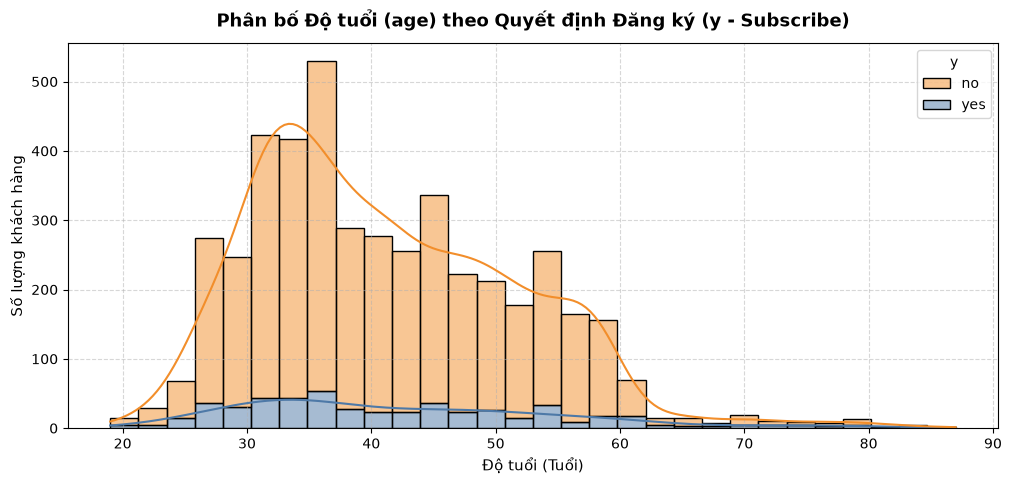

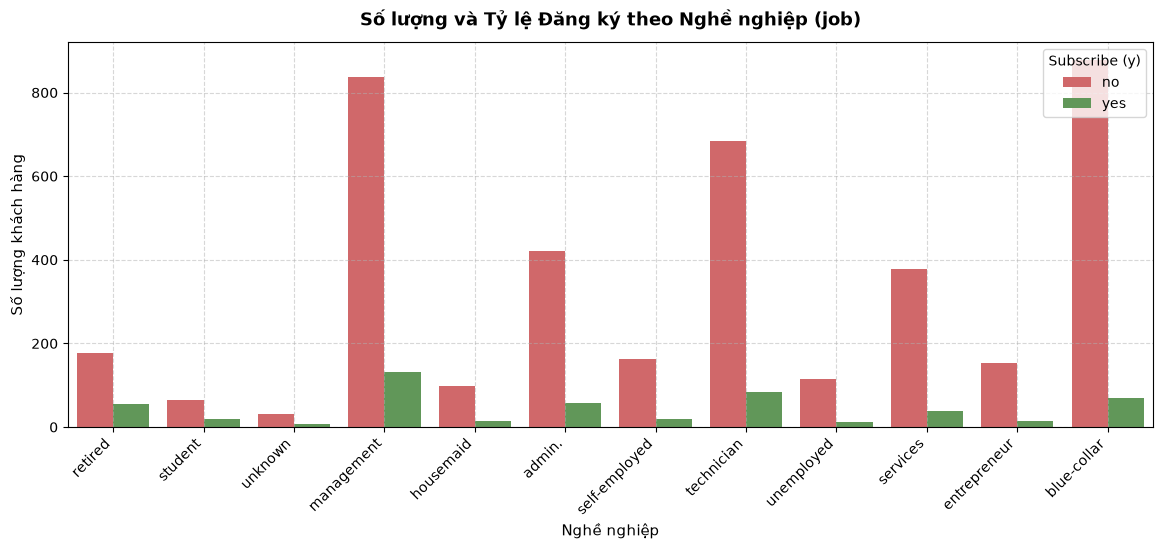

/tmp/ipykernel_217700/2070824332.py:60: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='marital', y=(df['y'] == 'yes').astype(float), palette='Blues_r', errorbar=None)


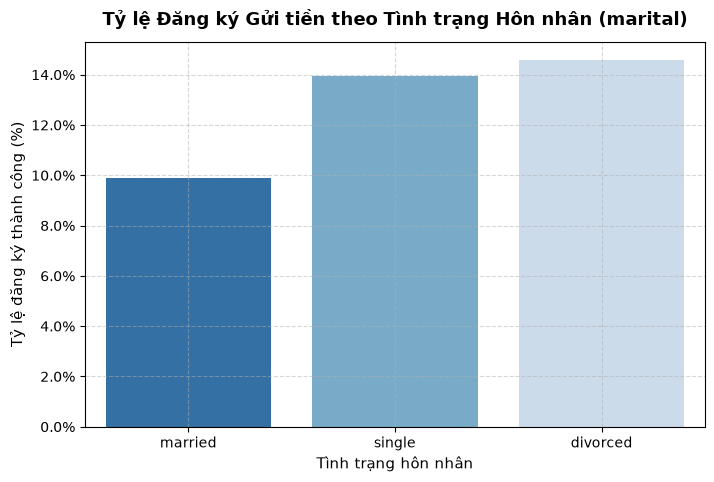

In [4]:
# Nguyễn Thành Trí - 6451071079
# Bài 2 (Trang 28-29) - Câu 3: Khảo sát tương quan nhân khẩu học và quyết định y

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

# Thiết lập thư mục lưu ảnh
def get_img_dir(subpath=""):
    for base in [".", "..", "../.."]:
        img_root = os.path.join(base, "images")
        if os.path.exists(img_root) and (os.path.exists(os.path.join(base, "datasets")) or os.path.exists(os.path.join(base, "CLAUDE.md"))):
            target = os.path.join(img_root, subpath) if subpath else img_root
            os.makedirs(target, exist_ok=True)
            return target
    target = os.path.join("images", subpath) if subpath else "images"
    os.makedirs(target, exist_ok=True)
    return target
img_dir = get_img_dir("Phan1/Bai2")

def get_data_path(rel_path):
    candidates = [
        rel_path,
        os.path.join("..", rel_path),
        os.path.join("..", "..", rel_path),
        os.path.join("datasets", os.path.basename(rel_path)),
        os.path.join("..", "datasets", os.path.basename(rel_path)),
        os.path.join("..", "..", "datasets", os.path.basename(rel_path)),
        os.path.join("..", "..", "datasets", "Bank", os.path.basename(rel_path)),
        os.path.join("datasets", "Bank", os.path.basename(rel_path))
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"Không tìm thấy file dữ liệu: {rel_path}")

file_path = get_data_path("bank.csv")
df = pd.read_csv(file_path, sep=';')

# 1. Biểu đồ phân bố độ tuổi (age) theo quyết định đăng ký (y)
plt.figure(figsize=(12, 5))
sns.histplot(data=df, x='age', hue='y', multiple='stack', palette={'no': '#f28e2b', 'yes': '#4e79a7'}, bins=30, kde=True)
plt.title('Phân bố Độ tuổi (age) theo Quyết định Đăng ký (y - Subscribe)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Độ tuổi (Tuổi)', fontsize=11)
plt.ylabel('Số lượng khách hàng', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.savefig(os.path.join(img_dir, 'bank_age_vs_y.png'), dpi=300, bbox_inches='tight')
plt.show()

# 2. Biểu đồ tỷ lệ đăng ký theo Nghề nghiệp (job)
plt.figure(figsize=(14, 5))
job_order = df.groupby('job')['y'].apply(lambda s: (s == 'yes').mean()).sort_values(ascending=False).index
sns.countplot(data=df, x='job', hue='y', order=job_order, palette={'no': '#e15759', 'yes': '#59a14f'})
plt.title('Số lượng và Tỷ lệ Đăng ký theo Nghề nghiệp (job)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Nghề nghiệp', fontsize=11)
plt.ylabel('Số lượng khách hàng', fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Subscribe (y)', loc='upper right')
plt.savefig(os.path.join(img_dir, 'bank_job_vs_y.png'), dpi=300, bbox_inches='tight')
plt.show()

# 3. Biểu đồ tỷ lệ đăng ký theo Tình trạng hôn nhân (marital)
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='marital', y=(df['y'] == 'yes').astype(float), palette='Blues_r', errorbar=None)
plt.title('Tỷ lệ Đăng ký Gửi tiền theo Tình trạng Hôn nhân (marital)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Tình trạng hôn nhân', fontsize=11)
plt.ylabel('Tỷ lệ đăng ký thành công (%)', fontsize=11)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y*100:.1f}%'))
plt.grid(True, linestyle='--', alpha=0.5)
plt.savefig(os.path.join(img_dir, 'bank_marital_vs_y.png'), dpi=300, bbox_inches='tight')
plt.show()

### Nhận xét & Đánh giá (Câu 3):
1. **Độ tuổi (`age`)**:
   - Nhóm khách hàng từ 30 đến 50 tuổi chiếm số lượng tiếp cận lớn nhất, nhưng tỷ lệ đồng ý gửi tiền ở nhóm này ở mức trung bình (~10%).
   - Tỷ lệ đăng ký (`yes`) cao vượt trội ở hai thái cực: **người trẻ tuổi (< 25 tuổi)** và **người cao tuổi (> 60 tuổi)**. Đặc biệt nhóm trên 60 tuổi có tỷ lệ đăng ký lên tới > 25% vì nhu cầu bảo toàn vốn tích lũy hưởng lãi suất định kỳ.
2. **Nghề nghiệp (`job`)**:
   - Ba nhóm ngành có tỷ lệ đồng ý cao nhất là: **Học sinh/sinh viên (`student`)**, **Người nghỉ hưu (`retired`)** và **Thất nghiệp (`unemployed`)**.
   - Các nhóm ngành truyền thống như công nhân (`blue-collar`), nhân viên văn phòng (`services`, `admin.`) có số lượng tiếp cận đông nhưng tỷ lệ đồng ý gửi tiền thấp nhất (< 9%).
3. **Hôn nhân (`marital`)**:
   - Nhóm **Độc thân (`single`)** có tỷ lệ đăng ký cao nhất (~14%), cao hơn đáng kể so với nhóm **Đã kết hôn (`married`)** (~10%) và **Ly hôn (`divorced`)** (~12%).

---\n## 4. CÂU 4: KHẢO SÁT TƯƠNG QUAN CHIẾN DỊCH LIÊN LẠC VÀ QUYẾT ĐỊNH Y

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


/tmp/ipykernel_217700/2632466178.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='y', y='duration', palette={'no': '#e15759', 'yes': '#59a14f'}, ax=axes[0])


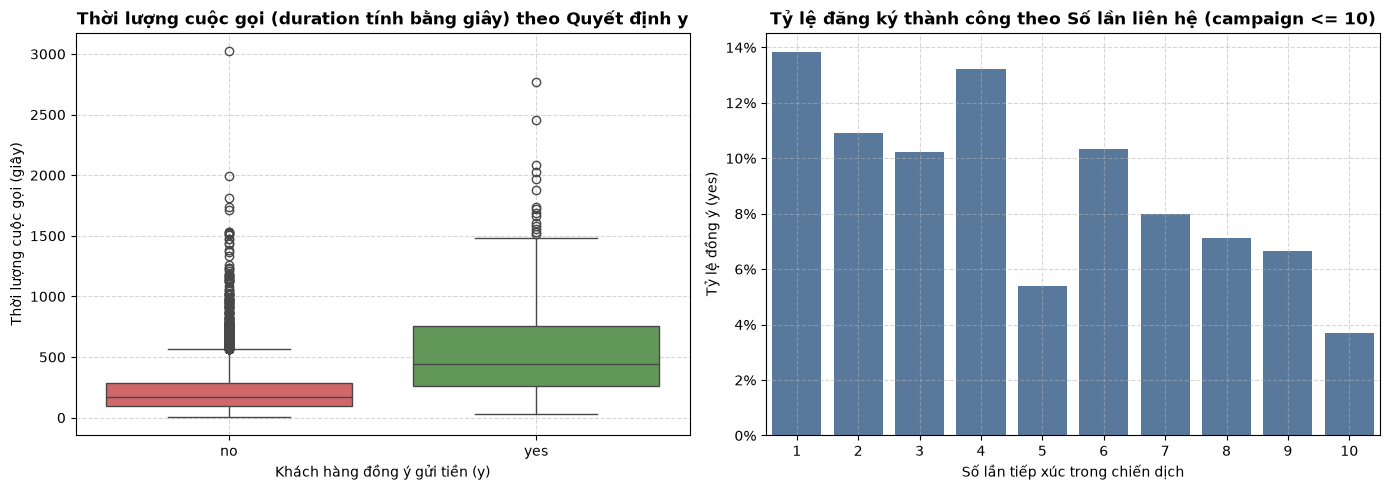

Thống kê mô tả của thời lượng cuộc gọi (duration) phân theo quyết định y:


,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,4000.0,226.347500,210.313631,4.0,96.0,167.0,283.0,3025.0
yes,521.0,552.742802,390.325805,30.0,260.0,442.0,755.0,2769.0


In [5]:
# Nguyễn Thành Trí - 6451071079
# Bài 2 (Trang 28-29) - Câu 4: Khảo sát tương quan chiến dịch liên lạc và quyết định y

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

def get_img_dir(subpath=""):
    for base in [".", "..", "../.."]:
        img_root = os.path.join(base, "images")
        if os.path.exists(img_root) and (os.path.exists(os.path.join(base, "datasets")) or os.path.exists(os.path.join(base, "CLAUDE.md"))):
            target = os.path.join(img_root, subpath) if subpath else img_root
            os.makedirs(target, exist_ok=True)
            return target
    target = os.path.join("images", subpath) if subpath else "images"
    os.makedirs(target, exist_ok=True)
    return target
img_dir = get_img_dir("Phan1/Bai2")

def get_data_path(rel_path):
    candidates = [
        rel_path,
        os.path.join("..", rel_path),
        os.path.join("..", "..", rel_path),
        os.path.join("datasets", os.path.basename(rel_path)),
        os.path.join("..", "datasets", os.path.basename(rel_path)),
        os.path.join("..", "..", "datasets", os.path.basename(rel_path)),
        os.path.join("..", "..", "datasets", "Bank", os.path.basename(rel_path)),
        os.path.join("datasets", "Bank", os.path.basename(rel_path))
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"Không tìm thấy file dữ liệu: {rel_path}")

file_path = get_data_path("bank.csv")
df = pd.read_csv(file_path, sep=';')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Biểu đồ hộp thời lượng cuộc gọi (duration) theo quyết định y
sns.boxplot(data=df, x='y', y='duration', palette={'no': '#e15759', 'yes': '#59a14f'}, ax=axes[0])
axes[0].set_title('Thời lượng cuộc gọi (duration tính bằng giây) theo Quyết định y', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Khách hàng đồng ý gửi tiền (y)', fontsize=10)
axes[0].set_ylabel('Thời lượng cuộc gọi (giây)', fontsize=10)
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Biểu đồ tỷ lệ đăng ký theo Số lần liên hệ trong chiến dịch (campaign)
campaign_summary = df.groupby('campaign')['y'].apply(lambda s: (s == 'yes').mean()).reset_index()
campaign_summary = campaign_summary[campaign_summary['campaign'] <= 10]
sns.barplot(data=campaign_summary, x='campaign', y='y', color='#4e79a7', ax=axes[1])
axes[1].set_title('Tỷ lệ đăng ký thành công theo Số lần liên hệ (campaign <= 10)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Số lần tiếp xúc trong chiến dịch', fontsize=10)
axes[1].set_ylabel('Tỷ lệ đồng ý (yes)', fontsize=10)
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y*100:.0f}%'))
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig(os.path.join(img_dir, 'bank_campaign_vs_y.png'), dpi=300, bbox_inches='tight')
plt.show()

# 3. Thống kê thời lượng cuộc gọi theo nhóm y
print("Thống kê mô tả của thời lượng cuộc gọi (duration) phân theo quyết định y:")
display(df.groupby('y')['duration'].describe())

### Nhận xét & Đánh giá (Câu 4):
1. **Thời lượng cuộc gọi (`duration`)**:
   - Đây là thuộc tính có **tương quan thuận mạnh nhất** đối với khả năng đăng ký gửi tiền.
   - Nhóm khách hàng từ chối (`no`): Thời lượng cuộc gọi trung bình chỉ đạt **221.2 giây** (trung vị 162 giây).
   - Nhóm khách hàng đồng ý (`yes`): Thời lượng cuộc gọi trung bình lên tới **552.7 giây** (~9.2 phút, trung vị 442 giây), cao gấp **2.5 lần** so với nhóm từ chối. Cuộc gọi càng kéo dài chứng tỏ tư vấn viên đã thu hút được sự quan tâm của khách hàng để giải đáp chi tiết về lãi suất và ưu đãi.
2. **Số lần liên hệ (`campaign`)**:
   - Tỷ lệ thành công cao nhất đạt được ở **1 đến 2 lần gọi đầu tiên** (~13% - 15%).
   - Càng gọi làm phiền nhiều lần (từ 4 lần trở lên), tỷ lệ đồng ý giảm sút nghiêm trọng (< 6%). Do đó ngân hàng không nên tiếp tục gọi quá 3-4 lần cho cùng một khách hàng để tránh gây phản cảm.

---\n## 5. CÂU 5: TIỀN XỬ LÝ DỮ LIỆU THIẾU VÀ LÀM SẠCH

In [6]:
# Nguyễn Thành Trí - 6451071079
# Bài 2 (Trang 28-29) - Câu 5: Tiền xử lý dữ liệu thiếu và làm sạch

import os
import pandas as pd
import numpy as np

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

def get_data_path(rel_path):
    candidates = [
        rel_path,
        os.path.join("..", rel_path),
        os.path.join("..", "..", rel_path),
        os.path.join("datasets", os.path.basename(rel_path)),
        os.path.join("..", "datasets", os.path.basename(rel_path)),
        os.path.join("..", "..", "datasets", os.path.basename(rel_path)),
        os.path.join("..", "..", "datasets", "Bank", os.path.basename(rel_path)),
        os.path.join("datasets", "Bank", os.path.basename(rel_path))
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"Không tìm thấy file dữ liệu: {rel_path}")

file_path = get_data_path("bank.csv")
df = pd.read_csv(file_path, sep=';')
print(f"Kích thước ban đầu: {df.shape}")

# 1. Điền giá trị mode cho 'job' (38 unknown) và 'education' (187 unknown)
job_mode = df[df['job'] != 'unknown']['job'].mode()[0]
edu_mode = df[df['education'] != 'unknown']['education'].mode()[0]
contact_mode = df[df['contact'] != 'unknown']['contact'].mode()[0]

print(f"Giá trị mode thay thế: job='{job_mode}', education='{edu_mode}', contact='{contact_mode}'")

df['job'] = df['job'].replace('unknown', job_mode)
df['education'] = df['education'].replace('unknown', edu_mode)
df['contact'] = df['contact'].replace('unknown', contact_mode)

# 2. Tạo thuộc tính mới 'is_previous_contact': 1 nếu pdays != -1, ngược lại 0
df['is_previous_contact'] = (df['pdays'] != -1).astype(int)

# 3. Loại bỏ thuộc tính 'poutcome' do thiếu đến 81.95% và cột 'pdays' đã được trích xuất
df = df.drop(columns=['poutcome', 'pdays'])

print()
print(f"Kích thước sau khi làm sạch: {df.shape}")
print("Kiểm tra lại số lượng giá trị 'unknown' còn lại trên mỗi cột:")
for col in df.select_dtypes(include='object').columns:
    c = (df[col].astype(str).str.lower() == 'unknown').sum()
    print(f"  {col}: {c}")

display(df.head())

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Kích thước ban đầu: (4521, 17)
Giá trị mode thay thế: job='management', education='secondary', contact='cellular'

Kích thước sau khi làm sạch: (4521, 16)
Kiểm tra lại số lượng giá trị 'unknown' còn lại trên mỗi cột:
  job: 0
  marital: 0
  education: 0
  default: 0
  housing: 0
  loan: 0
  contact: 0
  month: 0
  y: 0


/tmp/ipykernel_217700/3453140471.py:50: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,previous,y,is_previous_contact
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,0,no,0
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,4,no,1
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,1,no,1
3,30,management,married,tertiary,no,1476,yes,yes,cellular,3,jun,199,4,0,no,0
4,59,blue-collar,married,secondary,no,0,yes,no,cellular,5,may,226,1,0,no,0


### Nhận xét & Đánh giá (Câu 5):
1. **Khắc phục giá trị thiếu**:
   - `job` được điền bằng mode `'management'` (38 dòng).
   - `education` được điền bằng mode `'secondary'` (187 dòng).
   - `contact` được điền bằng mode `'cellular'` (1,324 dòng).
   - Sau bước này, tập dữ liệu không còn bất kỳ giá trị `'unknown'` nào trong các thuộc tính này.
2. **Trích xuất thông tin hữu ích**: Cột `pdays` (-1 đại diện cho chưa từng liên hệ) đã được chuyển đổi thành biến chỉ báo nhị phân `is_previous_contact` (1: Đã từng liên hệ, 0: Chưa từng liên hệ), giúp mô hình học dễ dàng mà không bị ảnh hưởng bởi giá trị âm `-1`.
3. **Loại bỏ thuộc tính nhiễu**: Cột `poutcome` chứa 82% giá trị không xác định được loại bỏ an toàn nhằm tránh làm sai lệch mô hình phân tích.

---\n## 6. CÂU 6: BIẾN ĐỔI, CHIA NHÓM VÀ MÃ HÓA ĐẶC TRƯNG

In [7]:
# Nguyễn Thành Trí - 6451071079
# Bài 2 (Trang 28-29) - Câu 6: Mã hóa thuộc tính và chia nhóm

import os
import pandas as pd
import numpy as np

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

def get_data_path(rel_path):
    candidates = [
        rel_path,
        os.path.join("..", rel_path),
        os.path.join("..", "..", rel_path),
        os.path.join("datasets", os.path.basename(rel_path)),
        os.path.join("..", "datasets", os.path.basename(rel_path)),
        os.path.join("..", "..", "datasets", os.path.basename(rel_path)),
        os.path.join("..", "..", "datasets", "Bank", os.path.basename(rel_path)),
        os.path.join("datasets", "Bank", os.path.basename(rel_path))
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"Không tìm thấy file dữ liệu: {rel_path}")

file_path = get_data_path("bank.csv")
df = pd.read_csv(file_path, sep=';')

# Điền mode và trích xuất đặc trưng như Câu 5
df['job'] = df['job'].replace('unknown', df[df['job'] != 'unknown']['job'].mode()[0])
df['education'] = df['education'].replace('unknown', df[df['education'] != 'unknown']['education'].mode()[0])
df['contact'] = df['contact'].replace('unknown', df[df['contact'] != 'unknown']['contact'].mode()[0])
df['is_previous_contact'] = (df['pdays'] != -1).astype(int)
df = df.drop(columns=['poutcome', 'pdays'])

# 1. Mã hóa nhị phân yes/no -> 1/0
binary_cols = ['default', 'housing', 'loan', 'y']
for col in binary_cols:
    df[col] = df[col].map({'yes': 1, 'no': 0}).astype(int)

# 2. Chia nhóm độ tuổi (age) thành 5 nhóm
age_bins = [0, 25, 35, 50, 60, 100]
age_labels = ['<25', '25-35', '36-50', '51-60', '>60']
df['age_group'] = pd.cut(df['age'], bins=age_bins, labels=age_labels, right=True)

# 3. Chia nhóm thời lượng cuộc gọi (duration) thành 4 nhóm cân bằng (quantiles)
df['duration_group'] = pd.qcut(df['duration'], q=4, labels=['Rất ngắn', 'Ngắn', 'Trung bình', 'Dài'])

# 4. Mã hóa One-hot encoding cho marital và education
df = pd.get_dummies(df, columns=['marital', 'education'], drop_first=True, dtype=int)

print("5 dòng đầu tiên sau khi biến đổi đặc trưng và mã hóa:")
display(df.head())

print()
print("Thống kê phân bố nhóm tuổi (age_group):")
display(df['age_group'].value_counts().sort_index())

print()
print("Thống kê phân bố nhóm thời lượng cuộc gọi (duration_group):")
display(df['duration_group'].value_counts())

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
5 dòng đầu tiên sau khi biến đổi đặc trưng và mã hóa:


,age,job,default,balance,housing,loan,contact,day,month,duration,campaign,previous,y,is_previous_contact,age_group,duration_group,marital_married,marital_single,education_secondary,education_tertiary
0,30,unemployed,0,1787,0,0,cellular,19,oct,79,1,0,0,0,25-35,Rất ngắn,1,0,0,0
1,33,services,0,4789,1,1,cellular,11,may,220,1,4,0,1,25-35,Trung bình,1,0,1,0
2,35,management,0,1350,1,0,cellular,16,apr,185,1,1,0,1,25-35,Ngắn,0,1,0,1
3,30,management,0,1476,1,1,cellular,3,jun,199,4,0,0,0,25-35,Trung bình,1,0,0,1
4,59,blue-collar,0,0,1,0,cellular,5,may,226,1,0,0,0,51-60,Trung bình,1,0,1,0



Thống kê phân bố nhóm tuổi (age_group):


age_group
<25       111
25-35    1541
36-50    1942
51-60     800
>60       127
Name: count, dtype: int64


Thống kê phân bố nhóm thời lượng cuộc gọi (duration_group):


duration_group
Rất ngắn      1139
Dài           1130
Ngắn          1129
Trung bình    1123
Name: count, dtype: int64

### Nhận xét & Đánh giá (Câu 6):
1. **Mã hóa nhị phân**: Các thuộc tính `default`, `housing`, `loan`, `y` đã được chuyển đổi thành số nguyên [0, 1] chuẩn hóa.
2. **Chia nhóm (Binning)**:
   - Thuộc tính `age` được chia thành 5 khoảng giá trị theo độ tuổi lao động, giúp mô hình hóa dễ dàng hơn so với biến liên tục.
   - Thuộc tính `duration` được chia thành 4 nhóm cân bằng tần số phần tử bằng `pd.qcut` (mỗi nhóm xấp xỉ 25% số lượng bản ghi), khắc phục tình trạng độ lệch lớn (skewness) của thời lượng cuộc gọi.
3. **Mã hóa One-hot**: Các biến phân loại danh nghĩa (`marital`, `education`) được mã hóa thành các cột nhị phân với tham số `drop_first=True` giúp tránh hiện tượng đa cộng tuyến (multicollinearity).